# 🧠 Home NIDS — Train Model (ตัวเทรนหลัก)

Notebook นี้คือที่เทรนโมเดลหลักของโปรเจกต์ รันจากบนลงล่างได้เลย (**Kernel → Restart & Run All**)

| ขั้น | ทำอะไร |
|---|---|
| 0 | ตั้งค่า (ดึงจาก `config/config.yaml` + โค้ดของ microservice) |
| 1 | แปลง `.pcap` → CSV (`training/pcap/normal/`, `training/pcap/test/`) |
| 2 | โหลดข้อมูลเทรน (traffic ปกติ) |
| 3 | ดูการกระจายของ feature |
| 4 | เทรน StandardScaler + Isolation Forest |
| 5 | สร้างชุดทดสอบที่มี label (ปกติ / โจมตี) |
| 6 | เลือก threshold |
| 7 | วัดผล: **Confusion Matrix (TP/FP/TN/FN), Accuracy, Precision, Recall, F1, FPR, ROC-AUC** |
| 8 | บันทึกโมเดลลง `system/models/` → detection-service ใช้ต่อทันที |

> **วิธีเพิ่ม dataset:** วาง `.pcap` traffic ปกติใน `training/pcap/normal/`, ไฟล์ที่มีการโจมตีใน `training/pcap/test/`
> แล้วเขียนกฎ label (IP ผู้โจมตี + ช่วงเวลา) ใน `training/pcap/labels.csv`
> ถ้ายังไม่มีไฟล์ notebook ยังรันได้ด้วยข้อมูลจำลอง

## 0. ตั้งค่า
ค่าทั้งหมดมาจาก `config/config.yaml` (ไฟล์เดียวกับที่ microservice ใช้) แก้ใน config หรือ override ในเซลล์นี้ได้

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "training" else Path.cwd()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "system"))   # โค้ดของระบบ: shared/, services/

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib import font_manager
_fonts = {f.name for f in font_manager.fontManager.ttflist}            # ใช้ฟอนต์ไทยเท่าที่มีในเครื่อง
plt.rcParams["font.family"] = [f for f in ("Tahoma", "Leelawadee UI", "Noto Sans Thai", "Loma") if f in _fonts] or ["DejaVu Sans"]

# ---- โค้ดของ microservice (ใช้ตัวเดียวกับตอนรันจริง) ----
from shared.config import load_config, resolve_path
from shared.features import FEATURE_NAMES, FEATURE_VERSION        # สูตร feature ของ feature-service
# ---- โค้ดฝั่ง training ----
from training.generate_data import generate, load_packets_csv
from training.pcap_to_csv import convert_folder, list_pcaps          # ใช้ packet_to_meta ของ capture-service
from training.common import (build_features, train_model, anomaly_scores, recommend_threshold,
                             make_scenarios, is_ping_scenario, save_artifacts, ping_request_scores,
                             score_scenarios, scan_report, SCAN_DETECT_WITHIN)
from training import evaluate as ev

cfg = load_config()
T = cfg["training"]

# ================= PARAMETERS (แก้ได้) =================
WINDOW_SEC     = cfg["feature"]["window_sec"]     # ต้องเท่ากับ feature-service
N_ESTIMATORS   = T["n_estimators"]
SEED           = T["seed"]
FP_QUANTILE    = T["fp_quantile"]
MAX_PACKETS    = T["max_packets_per_pcap"]        # อ่านไม่เกินกี่ packet ต่อไฟล์ pcap
NORMAL_DIR     = resolve_path(T["pcap_normal_dir"])
TEST_DIR       = resolve_path(T["pcap_test_dir"])
LABELS_FILE    = resolve_path(T["labels_file"])
PCAP_CSV_DIR   = resolve_path(T["pcap_csv_dir"])
TIME_WINDOWS   = T.get("pcap_time_windows") or {}   # อ่านเฉพาะช่วงเวลาของบางไฟล์ (เช่น Friday ช่วง PortScan)
CAPTURED_CSV   = resolve_path(cfg["capture"]["csv_path"])   # traffic จริงที่ capture บันทึกไว้ (capture.mode: csv|both)
# traffic ปกติของบ้านเพิ่มเติม (CSV รูปแบบเดียวกับ capture) — ต้องไม่มี ping/scan ปน
EXTRA_NORMAL_CSVS = [resolve_path("data/home_discord_normal.csv"),      # คุย Discord + ใช้งานปกติ (session2 ก่อน 21:33)
                     resolve_path("data/soak_active1_train.csv"),       # ใช้งานหลายอย่าง 13 พ.ย. 01:17-01:58
                     resolve_path("data/soak_night1_train.csv")]        # ข้ามคืน (Discord ค้าง) 13 พ.ย. 03:41-05:18
# ชุดทดสอบจาก traffic จริงของบ้าน (CSV) ติด label ด้วยกฎใน labels.csv เหมือน pcap ใน test/
EXTRA_TEST_CSVS   = [resolve_path("data/home_test_session2.csv"),       # Discord + ping + Fing scan จาก iPhone (session2 หลัง 21:33)
                     resolve_path("data/soak_active1_test.csv"),        # ใช้งานหลายอย่าง 01:58-02:18 (ปกติล้วน -> วัด alert หลอก)
                     resolve_path("data/soak_night1_test.csv")]         # ข้ามคืน 05:18-06:56 (ปกติล้วน -> วัด alert หลอก)

USE_SYNTHETIC   = True    # รวมข้อมูลปกติจำลอง (แนะนำ: ทำให้โมเดลรู้จัก ICMP ที่ dataset อาจไม่มี)
EXTRA_SYNTHETIC = 40_000  # สร้าง traffic ปกติจำลองเพิ่ม (ให้ ICMP/พฤติกรรมพื้นฐานไม่ถูก traffic จริงจำนวนมากกลบ) | 0 = ไม่เพิ่ม
USE_CAPTURED    = True    # รวม traffic จริงของบ้านจาก CAPTURED_CSV (ต้องไม่มี ping/scan ปนตอนเก็บ)
MAX_TRAIN_PER_SOURCE = 200_000   # สุ่มแถว (หลังคำนวณ feature) ให้แต่ละไฟล์ไม่เกินนี้ **ต่อโปรโตคอล** กัน dataset ใหญ่/UDP ของ Discord กลบ TCP ที่หายาก | None = ใช้ทั้งหมด
ICMP_MIN_FRAC   = 0.01    # ICMP ที่ไม่ใช่ ping ต้องมีอย่างน้อย ~1% ของข้อมูลเทรน (0.3% ไม่พอเมื่อมี traffic จริงเยอะ) ไม่งั้น tree ไม่แบ่งตาม ICMP แล้ว ping จะไม่ดูแปลก (README sec 4)
DROP_ICMP_ECHO  = True    # ตัด ping ออกจากข้อมูลเทรน (ไม่งั้นโมเดลจะเรียนว่า ping ปกติ)
USE_SIM_TEST    = True    # เพิ่มชุดทดสอบจำลอง (ping + nmap) เข้าไปในการวัดผล
FORCE_RECONVERT = False   # True = แปลง pcap ใหม่แม้มี CSV แล้ว
THRESHOLD_MODE  = "recommended"   # "recommended" | "best_f1" | หรือใส่ตัวเลข เช่น 0.63
# =======================================================

# ---- เก็บผลการเทรนทุกรอบ -> results/train_<วันเวลา>/ (report.md + รูป + metrics.json) ----
RUN_DIR = resolve_path("results") / time.strftime("train_%Y%m%d_%H%M%S")
RUN_DIR.mkdir(parents=True, exist_ok=True)
_REPORT = [f"# ผลการเทรน {time.strftime('%Y-%m-%d %H:%M:%S')}\n"]

def report(title, text=""):
    """เพิ่มหัวข้อลง report.md (เขียนไฟล์ทุกครั้ง ถ้ารันไม่จบก็ยังได้ผลถึงขั้นที่ทำเสร็จแล้ว)"""
    _REPORT.append(f"## {title}\n\n{text}\n")
    (RUN_DIR / "report.md").write_text("\n".join(_REPORT), encoding="utf-8")

def save_fig(fig, name):
    """บันทึกรูปลง RUN_DIR (ต้องเรียกก่อน plt.show())"""
    fig.savefig(RUN_DIR / name, dpi=120, bbox_inches="tight")

report("ตั้งค่า", ev.md_table([{
    "window_sec": WINDOW_SEC, "n_estimators": N_ESTIMATORS, "seed": SEED, "fp_quantile": FP_QUANTILE,
    "max_packets/pcap": MAX_PACKETS, "USE_SYNTHETIC": USE_SYNTHETIC, "USE_CAPTURED": USE_CAPTURED,
    "USE_SIM_TEST": USE_SIM_TEST, "DROP_ICMP_ECHO": DROP_ICMP_ECHO, "THRESHOLD_MODE": THRESHOLD_MODE,
    "MAX_TRAIN_PER_SOURCE": MAX_TRAIN_PER_SOURCE, "ICMP_MIN_FRAC": ICMP_MIN_FRAC,
    "EXTRA_SYNTHETIC": EXTRA_SYNTHETIC, "n_estimators": N_ESTIMATORS, "FEATURE_VERSION": FEATURE_VERSION}])
    + f"\n\nextra normal: `{[p.name for p in EXTRA_NORMAL_CSVS]}` | extra test: `{[p.name for p in EXTRA_TEST_CSVS]}`"
    + f"\n\ntime windows: `{TIME_WINDOWS}`")
print("เก็บผลรอบนี้ที่:", RUN_DIR)
print("config:", resolve_path("config/config.yaml"))
print(f"window={WINDOW_SEC}s  n_estimators={N_ESTIMATORS}  features={len(FEATURE_NAMES)} (v{FEATURE_VERSION})")

เก็บผลรอบนี้ที่: C:\Project_AI\Project-AI-IDS\results\train_20261113_142659
config: C:\Project_AI\Project-AI-IDS\config\config.yaml
window=5s  n_estimators=1000  features=25 (v3)


## 1. แปลง pcap → CSV
อ่านไฟล์ใน `training/pcap/normal/` และ `training/pcap/test/` แปลงด้วยฟังก์ชันเดียวกับ capture-service เก็บไว้ที่ `data/pcap_csv/` (ครั้งถัดไปใช้ของเดิม ไม่ต้องแปลงซ้ำ)

In [2]:
print("pcap traffic ปกติ :", [p.name for p in list_pcaps(NORMAL_DIR)] or "ไม่มี")
print("pcap สำหรับทดสอบ :", [p.name for p in list_pcaps(TEST_DIR)] or "ไม่มี")
t0 = time.time()
normal_csvs = convert_folder(NORMAL_DIR, PCAP_CSV_DIR, MAX_PACKETS, FORCE_RECONVERT, windows=TIME_WINDOWS)
test_csvs   = convert_folder(TEST_DIR,   PCAP_CSV_DIR, MAX_PACKETS, FORCE_RECONVERT, windows=TIME_WINDOWS)
test_csvs  += [p for p in EXTRA_TEST_CSVS if p.exists()]
print("CSV ทดสอบเพิ่มเติม:", [p.name for p in EXTRA_TEST_CSVS if p.exists()] or "ไม่มี")
print(f"เสร็จใน {time.time() - t0:.1f}s")

pcap traffic ปกติ : ['Monday-WorkingHours.pcap']
pcap สำหรับทดสอบ : ['Friday-WorkingHours.pcap']
ใช้ CSV เดิม (แปลงไว้แล้ว): normal__Monday-WorkingHours.csv
ใช้ CSV เดิม (แปลงไว้แล้ว): test__Friday-WorkingHours.csv
CSV ทดสอบเพิ่มเติม: ['home_test_session2.csv', 'soak_active1_test.csv', 'soak_night1_test.csv']
เสร็จใน 0.0s


## 2. โหลดข้อมูลเทรน (traffic ปกติเท่านั้น)
แต่ละไฟล์คำนวณ feature แยกกัน (sliding window ไม่ข้ามไฟล์) แล้วรวมเป็นชุดเดียว

In [3]:
sources = []
if USE_SYNTHETIC:
    syn = resolve_path(T["packets_csv"])
    if not syn.exists():                          # ยังไม่เคยสร้าง -> สร้างให้
        from training.generate_data import save_packets_csv
        save_packets_csv(generate(T["n_packets"], SEED), syn)
    sources.append(syn)
sources += normal_csvs
if USE_CAPTURED:
    if CAPTURED_CSV.exists():
        sources.append(CAPTURED_CSV)
    else:
        print(f"⚠️ USE_CAPTURED = True แต่ไม่พบ {CAPTURED_CSV} (ตั้ง capture.mode: both แล้วรัน run_all.py เพื่อเก็บ)")
    for extra_csv in EXTRA_NORMAL_CSVS:
        if extra_csv.exists():
            sources.append(extra_csv)
        else:
            print(f"⚠️ ไม่พบ {extra_csv} (ข้าม)")
assert sources, "ไม่มีข้อมูลเทรน: วาง pcap ใน training/pcap/normal/ หรือตั้ง USE_SYNTHETIC = True"

from collections import Counter
rng = np.random.default_rng(SEED)
blocks, summary = [], []
for src in sources:
    pk = load_packets_csv(src)
    n0 = len(pk)
    if DROP_ICMP_ECHO:
        pk = [p for p in pk if not (p["proto"] == "ICMP" and p["icmp_type"] in (0, 8))]
    n_ping = n0 - len(pk)
    pk.sort(key=lambda p: p["ts"])
    Xb = build_features(pk, WINDOW_SEC)          # คำนวณ feature จากไฟล์เต็มก่อน (ctx_* ต้องเห็น packet ต่อเนื่อง)
    if MAX_TRAIN_PER_SOURCE:                     # แล้วค่อยสุ่มแถว แยกตามโปรโตคอล (TCP/UDP/ICMP/อื่นๆ ไม่เกิน cap ต่อชนิด)
        protos = np.array([p["proto"] for p in pk])
        keep = []
        for pr in np.unique(protos):
            idx_p = np.flatnonzero(protos == pr)
            if len(idx_p) > MAX_TRAIN_PER_SOURCE:
                idx_p = rng.choice(idx_p, MAX_TRAIN_PER_SOURCE, replace=False)
            keep.append(idx_p)
        idx = np.sort(np.concatenate(keep)) if keep else np.arange(0)
        if len(idx) < len(Xb):
            Xb = Xb[idx]
            pk = [pk[i] for i in idx]
    blocks.append(Xb)
    c = Counter(p["proto"] for p in pk)
    summary.append({"ไฟล์": Path(src).name, "packets ทั้งไฟล์": n0, "ตัด ping": n_ping,
                    "ใช้เทรน": len(Xb), "TCP": c["TCP"], "UDP": c["UDP"], "ICMP": c["ICMP"], "อื่นๆ": c["OTHER"]})
if EXTRA_SYNTHETIC:
    extra_syn = generate(EXTRA_SYNTHETIC, SEED + 735)
    blocks.append(build_features(extra_syn, WINDOW_SEC))
    c = Counter(p["proto"] for p in extra_syn)
    summary.append({"ไฟล์": f"synthetic เพิ่ม (seed {SEED + 735})", "packets ทั้งไฟล์": len(extra_syn), "ตัด ping": 0,
                    "ใช้เทรน": len(extra_syn), "TCP": c["TCP"], "UDP": c["UDP"], "ICMP": c["ICMP"], "อื่นๆ": c["OTHER"]})
X = np.vstack(blocks)

# รักษาสัดส่วน ICMP (ไม่ใช่ ping) ให้ถึง ICMP_MIN_FRAC โดยทำสำเนาแถว ICMP ที่มีอยู่
icmp_col = FEATURE_NAMES.index("proto_icmp")
icmp_rows = np.flatnonzero(X[:, icmp_col] > 0.5)
n_icmp0, n_added = len(icmp_rows), 0
if ICMP_MIN_FRAC and n_icmp0 and n_icmp0 / len(X) < ICMP_MIN_FRAC:
    n_added = int(np.ceil((ICMP_MIN_FRAC * len(X) - n_icmp0) / (1 - ICMP_MIN_FRAC)))
    X = np.vstack([X, X[rng.choice(icmp_rows, n_added, replace=True)]])
elif ICMP_MIN_FRAC and not n_icmp0:
    print("⚠️ ไม่มี ICMP ในข้อมูลเทรนเลย -> ping จะไม่ถูกแยก (เปิด USE_SYNTHETIC = True)")
icmp_note = (f"ICMP (ไม่ใช่ ping): {n_icmp0:,} แถว ({n_icmp0 / max(len(X) - n_added, 1):.4%})"
             + (f" -> ทำสำเนาเพิ่ม {n_added:,} แถว ให้ได้ {ICMP_MIN_FRAC:.2%}" if n_added else ""))

display(Markdown(ev.md_table(summary)))
print(icmp_note)
print("รวม", X.shape[0], "packets x", X.shape[1], "features")
report("ข้อมูลเทรน (traffic ปกติ)", ev.md_table(summary) + f"\n\n{icmp_note}\n\nรวม {X.shape[0]:,} packets x {X.shape[1]} features")

| ไฟล์ | packets ทั้งไฟล์ | ตัด ping | ใช้เทรน | TCP | UDP | ICMP | อื่นๆ |
|---|---|---|---|---|---|---|---|
| normal_packets.csv | 8000 | 0 | 8000 | 6347 | 1626 | 27 | 0 |
| normal__Monday-WorkingHours.csv | 2000000 | 6 | 250215 | 200000 | 50140 | 0 | 75 |
| captured_packets.csv | 33160 | 0 | 33160 | 30082 | 3043 | 0 | 35 |
| home_discord_normal.csv | 146497 | 0 | 146497 | 835 | 145662 | 0 | 0 |
| soak_active1_train.csv | 1587441 | 4 | 219022 | 19013 | 200000 | 9 | 0 |
| soak_night1_train.csv | 1070773 | 0 | 208673 | 8672 | 200000 | 1 | 0 |
| synthetic เพิ่ม (seed 777) | 40000 | 0 | 40000 | 31927 | 7955 | 118 | 0 |

ICMP (ไม่ใช่ ping): 155 แถว (0.0171%) -> ทำสำเนาเพิ่ม 8,991 แถว ให้ได้ 1.00%
รวม 914558 packets x 25 features


## 3. ดูการกระจายของ feature

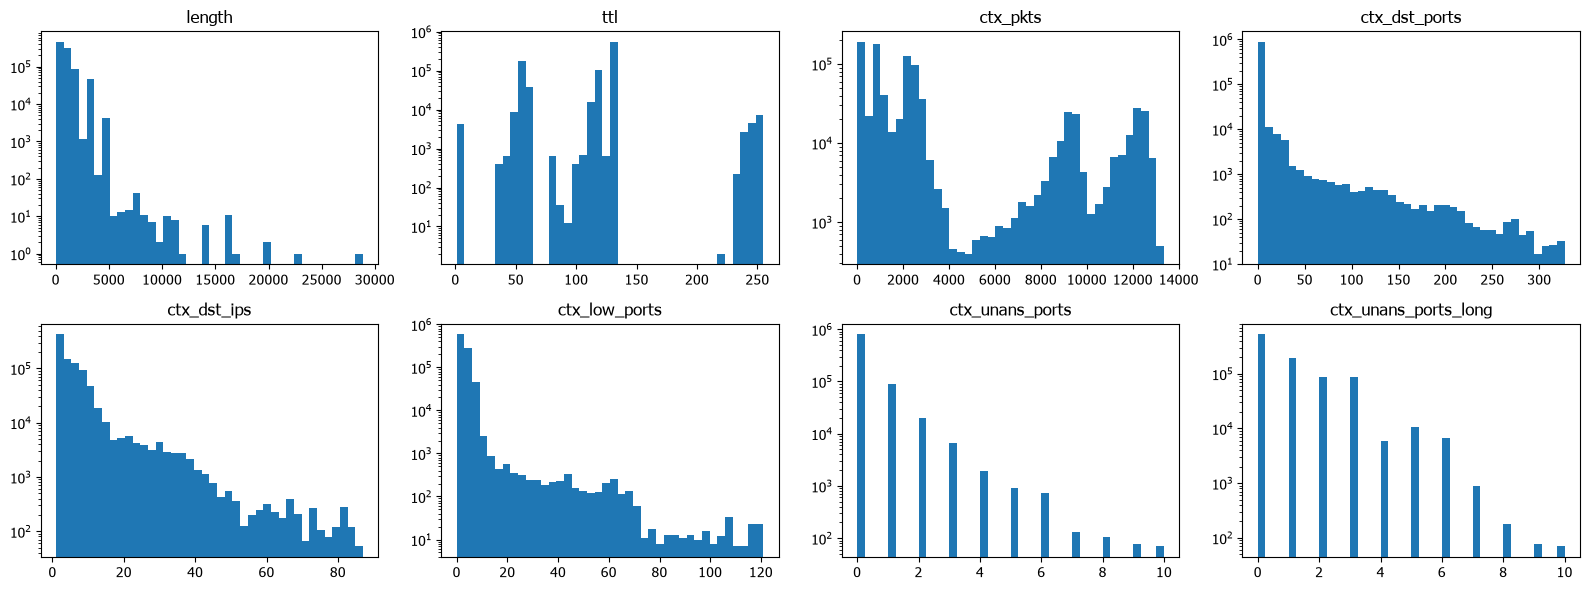

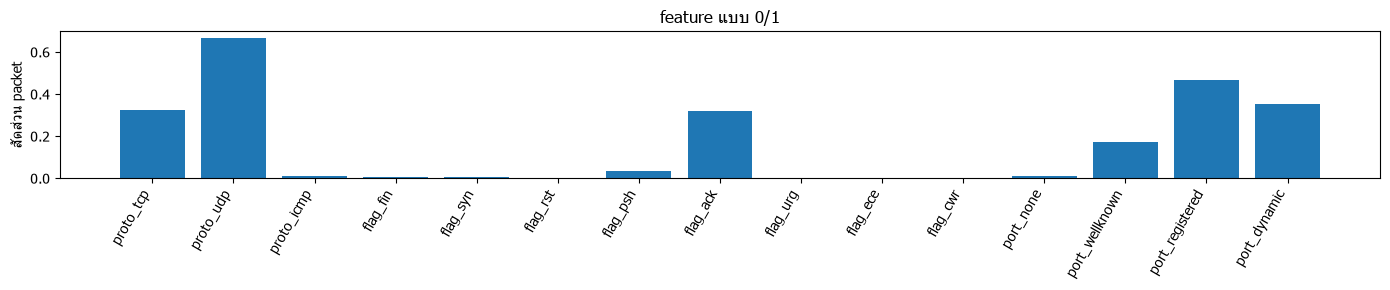

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, name in zip(axes.ravel(), ["length", "ttl", "ctx_pkts", "ctx_dst_ports",
                                   "ctx_dst_ips", "ctx_low_ports", "ctx_unans_ports", "ctx_unans_ports_long"]):
    ax.hist(X[:, FEATURE_NAMES.index(name)], bins=40, color="tab:blue")
    ax.set_title(name); ax.set_yscale("log")
fig.tight_layout(); save_fig(fig, "features_hist.png"); plt.show()

binary = [n for n in FEATURE_NAMES if n.startswith(("proto_", "flag_", "port_"))]
fig2 = plt.figure(figsize=(14, 3))
plt.bar(binary, [X[:, FEATURE_NAMES.index(n)].mean() for n in binary])
plt.xticks(rotation=60, ha="right"); plt.ylabel("สัดส่วน packet"); plt.title("feature แบบ 0/1")
plt.tight_layout(); save_fig(fig2, "features_binary.png"); plt.show()
report("การกระจายของ feature", "![](features_hist.png)\n\n![](features_binary.png)")

## 4. เทรน StandardScaler + Isolation Forest
เทรนด้วย traffic ปกติอย่างเดียว (unsupervised) — ไม่ต้องใช้ label

In [5]:
t0 = time.time()
scaler, model = train_model(X, N_ESTIMATORS, SEED)
s_train = anomaly_scores(model, scaler, X)
print(f"เทรนเสร็จใน {time.time() - t0:.1f}s | score ข้อมูลเทรน: median={np.median(s_train):.3f} "
      f"p99={np.quantile(s_train, .99):.3f} max={s_train.max():.3f}")
report("เทรน", f"ใช้เวลา {time.time() - t0:.1f}s | score ข้อมูลเทรน: median={np.median(s_train):.3f} "
       f"p99={np.quantile(s_train, .99):.3f} max={s_train.max():.3f}")

เทรนเสร็จใน 71.7s | score ข้อมูลเทรน: median=0.377 p99=0.581 max=0.759


## 5. ชุดทดสอบที่มี label
- **จำลอง** (`USE_SIM_TEST`): traffic ปกติชุดใหม่ (seed ต่างจากตอนเทรน) + ping + nmap หลายแบบ
- **จาก pcap** ใน `training/pcap/test/`: ติด label ด้วยกฎใน `labels.csv` (packet ที่ไม่ตรงกฎ = ปกติ)

In [6]:
rules = ev.load_label_rules(LABELS_FILE)
# เก็บแค่ feature + label ต่อชุด (ไม่เก็บ packet ทั้งหมดไว้ใน RAM)
test_parts = []   # (ชื่อ, X, label names, ระยะเวลา ชม.)
if USE_SIM_TEST:
    Xs, _, ns = ev.blocks_to_xy(ev.simulated_test_set(4000, SEED + 4200, WINDOW_SEC), WINDOW_SEC)
    test_parts.append(("จำลอง (ping + nmap)", Xs, ns, None))
for csv_path in test_csvs:
    pk = sorted(load_packets_csv(csv_path), key=lambda p: p["ts"])
    if not pk:
        continue
    names = np.array(ev.label_packets(pk, rules), dtype=object)
    n_att = int((names != ev.NORMAL).sum())
    print(f"{csv_path.name}: {len(pk):,} packets, ติด label โจมตี {n_att:,}")
    if not rules:
        print("  ⚠️ labels.csv ยังไม่มีกฎ -> ทุก packet ถูกนับเป็นปกติ")
    elif n_att == 0 and not csv_path.name.startswith("soak_"):
        print("  ⚠️ ไม่มี packet ไหนตรงกฎใน labels.csv -> เช็ก IP / ช่วงเวลา / timezone ในกฎ และ pcap_time_windows ใน config")
    hours = (pk[-1]["ts"] - pk[0]["ts"]) / 3600
    test_parts.append((csv_path.name, build_features(pk, WINDOW_SEC), names, hours))
    del pk
assert test_parts, "ไม่มีชุดทดสอบ: ตั้ง USE_SIM_TEST = True หรือวาง pcap ใน training/pcap/test/"

test_info = [{"ชุด": n, "packets": len(ns), "ติด label โจมตี": int((ns != ev.NORMAL).sum()),
              "ชั่วโมง": round(h, 2) if h else "-"} for n, _, ns, h in test_parts]
X_test = np.vstack([p[1] for p in test_parts])
names_test = np.concatenate([p[2] for p in test_parts])
y_test = (names_test != ev.NORMAL).astype(int)
s_test = anomaly_scores(model, scaler, X_test)
print(f"ชุดทดสอบ: {len(y_test):,} packets | ปกติ {int((y_test == 0).sum()):,} | โจมตี {int(y_test.sum()):,}")
report("ชุดทดสอบ", ev.md_table(test_info) + f"\n\nรวม {len(y_test):,} packets | ปกติ {int((y_test == 0).sum()):,} "
       f"| โจมตี {int(y_test.sum()):,}\n\nกฎใน labels.csv: {len(rules)} ข้อ")

test__Friday-WorkingHours.csv: 1,624,499 packets, ติด label โจมตี 324,062


home_test_session2.csv: 222,254 packets, ติด label โจมตี 964


soak_active1_test.csv: 821,434 packets, ติด label โจมตี 0


soak_night1_test.csv: 984,961 packets, ติด label โจมตี 0


ชุดทดสอบ: 3,659,132 packets | ปกติ 3,332,122 | โจมตี 327,010


## 6. เลือก threshold
- **recommended**: กึ่งกลางระหว่าง score ของ traffic ปกติ (quantile `fp_quantile`) กับ ping ต่ำสุด — ไม่ได้ดูชุดทดสอบ (ยุติธรรม)
- **best_f1**: ค่าที่ให้ F1 สูงสุดบนชุดทดสอบ — ⚠️ ได้ตัวเลขสวยเกินจริง เพราะเลือกจากชุดที่ใช้วัดผลเอง

In [7]:
# threshold แนะนำ: ใช้ traffic ปกติจำลองชุดแยก (validation) + ping จำลอง — ไม่แตะชุดทดสอบ
val = [p for p in generate(4000, SEED + 1) if p["proto"] != "ICMP"]
s_val = anomaly_scores(model, scaler, build_features(val, WINDOW_SEC))
s_ping = ping_request_scores(model, scaler, WINDOW_SEC)      # เฉพาะ echo request (ping ขาเข้า)
thr_rec, note = recommend_threshold(s_val, s_ping, FP_QUANTILE)
thr_f1 = ev.best_f1_threshold(y_test, s_test)
THRESHOLD = {"recommended": thr_rec, "best_f1": thr_f1}.get(THRESHOLD_MODE, THRESHOLD_MODE)
THRESHOLD = float(THRESHOLD)
print(f"recommended = {thr_rec:.4f}  ({note})")
print(f"best_f1     = {thr_f1:.4f}")
print(f"ใช้ THRESHOLD = {THRESHOLD:.4f}  (โหมด {THRESHOLD_MODE})")

grid = sorted(set(np.round(np.arange(0.55, 0.76, 0.02), 3).tolist() + [round(thr_rec, 4), round(thr_f1, 4)]))
sweep = ev.threshold_sweep(y_test, s_test, grid)
cols = ["threshold", "TP", "FP", "TN", "FN", "Accuracy", "Precision", "Recall (TPR)", "F1", "FPR"]
sweep_md = ev.md_table([{c: r[c] for c in cols} for r in sweep])
display(Markdown("**ผลที่ threshold ต่างๆ** (เลื่อนสูง = alert หลอกน้อยลง แต่จับพลาดมากขึ้น)\n\n" + sweep_md))
report("Threshold", f"- recommended = {thr_rec:.4f} ({note})\n- best_f1 = {thr_f1:.4f}\n"
       f"- **ใช้ {THRESHOLD:.4f}** (โหมด {THRESHOLD_MODE})\n\n" + sweep_md)

recommended = 0.6436  (OK: แยก ping ออกจาก traffic ปกติได้ (วางที่ 25% ของช่องว่างจากฝั่งปกติ))
best_f1     = 0.6292
ใช้ THRESHOLD = 0.6436  (โหมด recommended)


**ผลที่ threshold ต่างๆ** (เลื่อนสูง = alert หลอกน้อยลง แต่จับพลาดมากขึ้น)

| threshold | TP | FP | TN | FN | Accuracy | Precision | Recall (TPR) | F1 | FPR |
|---|---|---|---|---|---|---|---|---|---|
| 0.5500 | 325848 | 260350 | 3071772 | 1162 | 0.9285 | 0.5559 | 0.9964 | 0.7136 | 0.0781 |
| 0.5700 | 325687 | 176710 | 3155412 | 1323 | 0.9513 | 0.6483 | 0.9960 | 0.7853 | 0.0530 |
| 0.5900 | 323961 | 105296 | 3226826 | 3049 | 0.9704 | 0.7547 | 0.9907 | 0.8567 | 0.0316 |
| 0.6100 | 305813 | 54285 | 3277837 | 21197 | 0.9794 | 0.8492 | 0.9352 | 0.8901 | 0.0163 |
| 0.6292 | 299822 | 22369 | 3309753 | 27188 | 0.9865 | 0.9306 | 0.9169 | 0.9237 | 0.0067 |
| 0.6300 | 298896 | 20904 | 3311218 | 28114 | 0.9866 | 0.9346 | 0.9140 | 0.9242 | 0.0063 |
| 0.6436 | 272095 | 8982 | 3323140 | 54915 | 0.9825 | 0.9680 | 0.8321 | 0.8949 | 0.0027 |
| 0.6500 | 259050 | 6370 | 3325752 | 67960 | 0.9797 | 0.9760 | 0.7922 | 0.8745 | 0.0019 |
| 0.6700 | 248320 | 1302 | 3330820 | 78690 | 0.9781 | 0.9948 | 0.7594 | 0.8613 | 0.0004 |
| 0.6900 | 245681 | 513 | 3331609 | 81329 | 0.9776 | 0.9979 | 0.7513 | 0.8572 | 0.0002 |
| 0.7100 | 243714 | 233 | 3331889 | 83296 | 0.9772 | 0.9990 | 0.7453 | 0.8537 | 0.0001 |
| 0.7300 | 237653 | 86 | 3332036 | 89357 | 0.9756 | 0.9996 | 0.7267 | 0.8416 | 0.0000 |
| 0.7500 | 163726 | 2 | 3332120 | 163284 | 0.9554 | 1.0000 | 0.5007 | 0.6673 | 0.0000 |

## 7. ผลการวัด — Confusion Matrix และ Metrics

In [8]:
y_pred = (s_test >= THRESHOLD).astype(int)
m = ev.binary_metrics(y_test, y_pred)
m["ROC-AUC"] = ev.auc(y_test, s_test)

cm_md = f"""
### Confusion Matrix (threshold = {THRESHOLD:.4f})
| | ทำนาย: ปกติ | ทำนาย: โจมตี |
|---|---|---|
| **จริง: ปกติ** | TN = {m['TN']:,} | FP = {m['FP']:,} |
| **จริง: โจมตี** | FN = {m['FN']:,} | TP = {m['TP']:,} |

- **TP** จับการโจมตีได้ถูก · **FN** การโจมตีที่หลุด
- **FP** alert หลอก (ปกติแต่ถูกมองว่าแปลก) · **TN** ปกติและตอบว่าปกติ
"""
label_md = ev.md_table(ev.per_label_table(names_test, y_pred))
# แยกตามชุดทดสอบ: alert หลอกต่อชุด (+ ต่อชั่วโมงสำหรับ traffic จริง) และอัตราที่จับได้
file_rows, off = [], 0
for tname, _, ns, hours in test_parts:
    yp = y_pred[off:off + len(ns)]; off += len(ns)
    norm = ns == ev.NORMAL
    file_rows.append({"ชุด": tname, "packets ปกติ": int(norm.sum()), "packet หลอก": int(yp[norm].sum()),
                      "อัตรา alert หลอก": float(yp[norm].mean()) if norm.any() else 0.0,
                      "packet หลอก/ชม.": round(float(yp[norm].sum()) / hours, 1) if hours else "-",
                      "packets โจมตี": int((~norm).sum()),
                      "จับได้": float(yp[~norm].mean()) if (~norm).any() else "-"})
file_md = ev.md_table(file_rows)
display(Markdown("### แยกตามชุดทดสอบ\n" + file_md))
report("แยกตามชุดทดสอบ", file_md)
display(Markdown(cm_md))
display(Markdown("### Metrics\n" + ev.metrics_md(m)))
display(Markdown("### แยกตาม label\n(แถว normal = อัตรา alert หลอก, แถวโจมตี = อัตราที่จับได้)\n\n" + label_md))
report("ผลการวัด", cm_md + "\n### Metrics\n" + ev.metrics_md(m) +
       "\n\n### แยกตาม label\n(แถว normal = อัตรา alert หลอก, แถวโจมตี = อัตราที่จับได้)\n\n" + label_md)
import json
(RUN_DIR / "metrics.json").write_text(json.dumps(
    {"threshold": THRESHOLD, "threshold_mode": str(THRESHOLD_MODE),
     **{k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in m.items()}},
    ensure_ascii=False, indent=2, default=str), encoding="utf-8")

### แยกตามชุดทดสอบ
| ชุด | packets ปกติ | packet หลอก | อัตรา alert หลอก | packet หลอก/ชม. | packets โจมตี | จับได้ |
|---|---|---|---|---|---|---|
| จำลอง (ping + nmap) | 4000 | 11 | 0.0027 | - | 1984 | 0.8886 |
| test__Friday-WorkingHours.csv | 1300437 | 8884 | 0.0068 | 5076.7000 | 324062 | 0.8310 |
| home_test_session2.csv | 221290 | 0 | 0.0000 | 0.0000 | 964 | 0.9959 |
| soak_active1_test.csv | 821434 | 28 | 0.0000 | 82.5000 | 0 | - |
| soak_night1_test.csv | 984961 | 0 | 0.0000 | 0.0000 | 0 | - |


### Confusion Matrix (threshold = 0.6436)
| | ทำนาย: ปกติ | ทำนาย: โจมตี |
|---|---|---|
| **จริง: ปกติ** | TN = 3,323,199 | FP = 8,923 |
| **จริง: โจมตี** | FN = 54,992 | TP = 272,018 |

- **TP** จับการโจมตีได้ถูก · **FN** การโจมตีที่หลุด
- **FP** alert หลอก (ปกติแต่ถูกมองว่าแปลก) · **TN** ปกติและตอบว่าปกติ


### Metrics
| metric | ค่า |
|---|---|
| Accuracy | 0.9825 |
| Precision | 0.9682 |
| Recall (TPR) | 0.8318 |
| F1 | 0.8949 |
| FPR | 0.0027 |
| Specificity (TNR) | 0.9973 |
| Balanced Acc | 0.9146 |
| ROC-AUC | 0.9971 |

### แยกตาม label
(แถว normal = อัตรา alert หลอก, แถวโจมตี = อัตราที่จับได้)

| label | packets | ถูกมองว่าแปลก | อัตรา |
|---|---|---|---|
| normal | 3332122 | 8923 | 0.0027 |
| Ping-iPhone | 12 | 12 | 1.0000 |
| PortScan | 324062 | 269295 | 0.8310 |
| PortScan-Fing | 952 | 948 | 0.9958 |
| nmap: nmap -sS 100 port | 100 | 100 | 1.0000 |
| nmap: nmap -sS 1000 port | 1000 | 1000 | 1.0000 |
| nmap: nmap -sS ไล่ host (port 22 x100) | 100 | 90 | 0.9000 |
| nmap: nmap -sT (connect) 200 port | 200 | 200 | 1.0000 |
| nmap: nmap -sU (UDP) 100 port | 100 | 92 | 0.9200 |
| nmap: nmap -sn ไล่ host (ping sweep) | 400 | 236 | 0.5900 |
| ping: ping จากเครื่อง Linux/Mac | 8 | 5 | 0.6250 |
| ping: ping จากเครื่อง Windows | 8 | 5 | 0.6250 |
| ping: ping ตัวเอง (loopback, Windows) | 8 | 4 | 0.5000 |
| ping: ping รัว (flood เล็กน้อย) | 60 | 31 | 0.5167 |

415

In [9]:
# ---- เกณฑ์ผ่านตาม README: ต้องผ่านครบก่อนเอาโมเดลไปใช้แทนตัวเดิม ----
scen = score_scenarios(model, scaler, WINDOW_SEC)
_sc = make_scenarios()
ping_req = {k: s[np.array([p["icmp_type"] == 8 for p in _sc[k]])] for k, s in scen.items() if is_ping_scenario(k)}
scans = scan_report({k: s for k, s in scen.items() if not is_ping_scenario(k)}, THRESHOLD)
lab = {r["label"]: r["อัตรา"] for r in ev.per_label_table(names_test, y_pred)}
checks = []
for k, s in ping_req.items():
    checks.append({"เกณฑ์": f"ping (request) {k}", "ผล": f"{(s >= THRESHOLD).mean():.0%}", "ผ่าน": bool((s >= THRESHOLD).all())})
for k, r in scans.items():
    checks.append({"เกณฑ์": f"{k} จับได้ภายใน {SCAN_DETECT_WITHIN} packet แรก",
                   "ผล": f"packet ที่ {r['first']} (จับได้ {r['rate']:.0%})" if r["first"] else "จับไม่ได้", "ผ่าน": bool(r["ok"])})
for name in ("Ping-iPhone", "PortScan-Fing"):
    if name in lab:
        checks.append({"เกณฑ์": f"ของจริงในบ้าน: {name}", "ผล": f"{lab[name]:.1%}", "ผ่าน": bool(lab[name] >= 0.95)})
for r in file_rows:
    if r["ชุด"].startswith("soak_"):
        checks.append({"เกณฑ์": f"alert หลอก {r['ชุด']} (ข้อมูล)", "ผล": f"{r['packet หลอก']} packets ({r['packet หลอก/ชม.']}/ชม.)", "ผ่าน": "-"})
PASS = all(c["ผ่าน"] for c in checks if c["ผ่าน"] != "-")
gate_md = ev.md_table(checks) + ("\n\n**✅ ผ่านเกณฑ์ README ครบ**" if PASS else "\n\n**❌ ไม่ผ่านเกณฑ์ README — อย่าเอาโมเดลนี้ไปใช้ (กู้โมเดลเดิมจาก backup)**")
display(Markdown("### เกณฑ์ผ่านตาม README\n" + gate_md))
report("เกณฑ์ผ่านตาม README", gate_md)

### เกณฑ์ผ่านตาม README
| เกณฑ์ | ผล | ผ่าน |
|---|---|---|
| ping (request) ping ตัวเอง (loopback, Windows) | 100% | True |
| ping (request) ping จากเครื่อง Windows | 100% | True |
| ping (request) ping จากเครื่อง Linux/Mac | 100% | True |
| ping (request) ping รัว (flood เล็กน้อย) | 100% | True |
| nmap -sS 100 port จับได้ภายใน 40 packet แรก | packet ที่ 1 (จับได้ 100%) | True |
| nmap -sS 1000 port จับได้ภายใน 40 packet แรก | packet ที่ 1 (จับได้ 100%) | True |
| nmap -sT (connect) 200 port จับได้ภายใน 40 packet แรก | packet ที่ 1 (จับได้ 100%) | True |
| nmap -sU (UDP) 100 port จับได้ภายใน 40 packet แรก | packet ที่ 9 (จับได้ 92%) | True |
| nmap -sS ไล่ host (port 22 x100) จับได้ภายใน 40 packet แรก | packet ที่ 11 (จับได้ 90%) | True |
| nmap -sn ไล่ host (ping sweep) จับได้ภายใน 40 packet แรก | packet ที่ 1 (จับได้ 59%) | True |
| ของจริงในบ้าน: Ping-iPhone | 100.0% | True |
| ของจริงในบ้าน: PortScan-Fing | 99.6% | True |
| alert หลอก soak_active1_test.csv (ข้อมูล) | 28 packets (82.5/ชม.) | - |
| alert หลอก soak_night1_test.csv (ข้อมูล) | 0 packets (0.0/ชม.) | - |

**✅ ผ่านเกณฑ์ README ครบ**

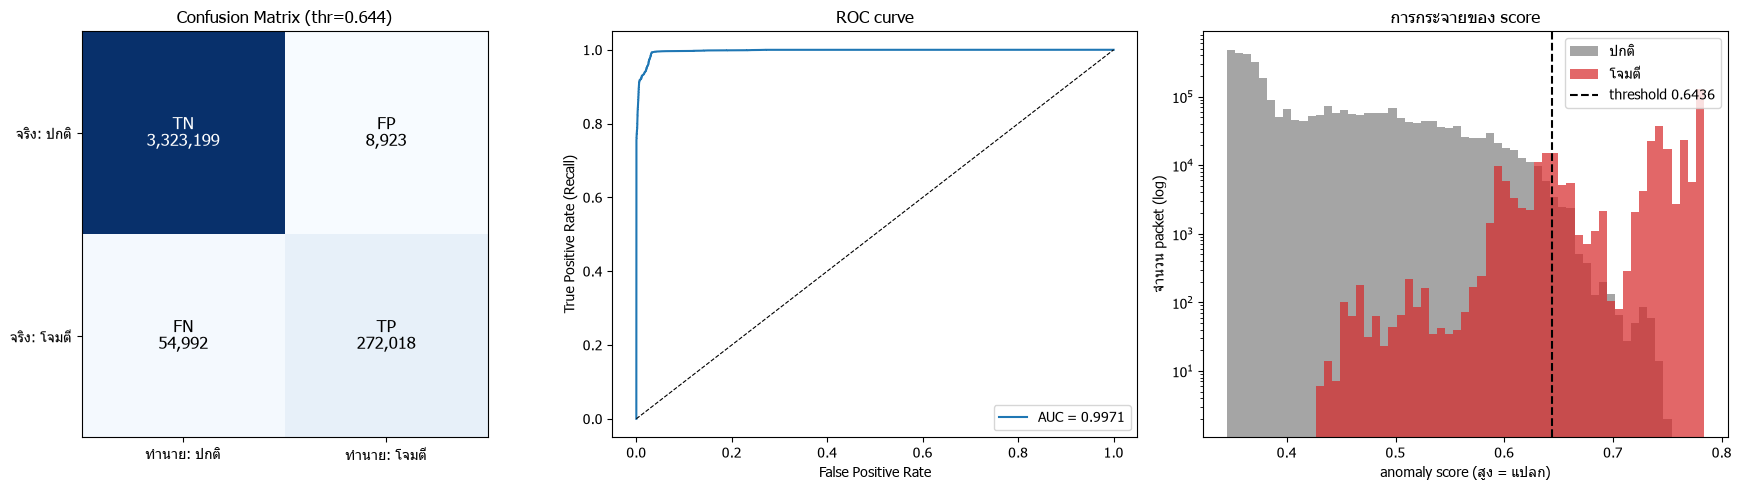

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ev.plot_confusion(m, axes[0], f"Confusion Matrix (thr={THRESHOLD:.3f})")
ev.plot_roc(y_test, s_test, axes[1])
ev.plot_score_hist(y_test, s_test, THRESHOLD, axes[2])
fig.tight_layout(); save_fig(fig, "confusion_roc_hist.png"); plt.show()
report("กราฟ Confusion Matrix / ROC / score", "![](confusion_roc_hist.png)")

> **อ่านผลอย่างไร:** dataset IDS มี traffic ปกติเยอะกว่าการโจมตีมาก **Accuracy อย่างเดียวหลอกตา**
> ให้ดู **Recall** (จับการโจมตีได้กี่ %), **FPR** (alert หลอกกี่ %) และ **F1** ควบคู่
> ส่วน nmap จะหลุดช่วงแรกๆ (FN) เป็นเรื่องปกติ เพราะต้องรอให้ window 5 วินาทีเห็นพฤติกรรมก่อน

## 8. บันทึกโมเดล
บันทึกลง `system/models/` → detection-service โหลดใช้ทันทีเมื่อรีสตาร์ท (`detection.threshold: auto` ใน config จะใช้ threshold นี้)

In [11]:
extra = {
    "threshold_mode": str(THRESHOLD_MODE),
    "test_metrics": {k: (round(v, 5) if isinstance(v, float) else v) for k, v in m.items()},
    "test_packets": int(len(y_test)),
}
src_names = ", ".join(Path(s).name for s in sources)
paths = save_artifacts(model, scaler, THRESHOLD, len(X), src_names, cfg, extra)
for k, p in paths.items():
    print(f"{k:12} -> {p}")
import shutil
if Path(paths.get("meta_path", "")).exists():
    shutil.copy(paths["meta_path"], RUN_DIR / "meta.json")
report("บันทึกโมเดล", "\n".join(f"- {k}: `{p}`" for k, p in paths.items()) + f"\n- แหล่งข้อมูลเทรน: {src_names}")
print("ผลการเทรนรอบนี้ (รูป + report.md):", RUN_DIR)
if str(cfg["detection"].get("threshold", "auto")).lower() != "auto":
    print("⚠️ config detection.threshold เป็นตัวเลข -> detection-service จะใช้ค่าใน config แทนค่าที่บันทึกนี้")
print("\nขั้นต่อไป: ปิด run_all.py เดิม (Ctrl+C) แล้วรันใหม่ เพื่อโหลดโมเดลใหม่")

model_path   -> C:\Project_AI\Project-AI-IDS\system\models\iforest.joblib
scaler_path  -> C:\Project_AI\Project-AI-IDS\system\models\scaler.joblib
meta_path    -> C:\Project_AI\Project-AI-IDS\system\models\meta.json
ผลการเทรนรอบนี้ (รูป + report.md): C:\Project_AI\Project-AI-IDS\results\train_20261113_142659

ขั้นต่อไป: ปิด run_all.py เดิม (Ctrl+C) แล้วรันใหม่ เพื่อโหลดโมเดลใหม่
